In [ ]:

# TRAVEL TIME PREDICTION: URBAN-RURAL ML MODEL
# Project priti gupta 
# STEP 1: Data Loading & Exploratory Data Analysis (EDA)

from google.colab import files
import pandas as pd
import io

print("Please upload your 'travel_time_dataset.csv' file:")
uploaded = files.upload()

# Dynamically read the uploaded CSV file
file_name = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("\n--- Basic Information ---")
print(df.info())

print("\n--- Checking for Missing Values ---")
print(df.isnull().sum())

print("\n--- First 5 Rows of the Dataset ---")
display(df.head())

Please upload your 'travel_time_dataset.csv' file:


Saving travel_time_dataset (1).csv to travel_time_dataset (1).csv

--- Basic Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   area_type            3000 non-null   object 
 1   distance_km          3000 non-null   float64
 2   road_type            3000 non-null   object 
 3   speed_limit_kmph     3000 non-null   float64
 4   num_traffic_signals  3000 non-null   int64  
 5   num_stops            3000 non-null   int64  
 6   population_density   3000 non-null   float64
 7   weather              3000 non-null   object 
 8   time_of_day          3000 non-null   object 
 9   travel_time_minutes  3000 non-null   float64
dtypes: float64(4), int64(2), object(4)
memory usage: 234.5+ KB
None

--- Checking for Missing Values ---
area_type              0
distance_km            0
road_type              0
speed_limit_kmph   

,area_type,distance_km,road_type,speed_limit_kmph,num_traffic_signals,num_stops,population_density,weather,time_of_day,travel_time_minutes
0,Urban,12.16,Main Road,46.3,9,3,10153.0,Clear,Night,29.20
1,Rural,29.54,Street,31.7,0,1,876.0,Rain,Night,69.98
2,Rural,20.51,Main Road,49.8,0,1,381.0,Clear,Evening Peak,25.84
3,Rural,30.26,Street,27.9,0,1,648.0,Clear,Evening Peak,72.30
4,Urban,5.22,Street,20.0,8,3,7518.0,Clear,Evening Peak,37.27


In [2]:

# STEP 2: Data Preprocessing

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Drop any rows with missing values (if any exist)
df = df.dropna()

# Define our target variable and feature columns
target = "travel_time_minutes"
categorical_cols = ["area_type", "road_type", "weather", "time_of_day"]
numeric_cols = ["distance_km", "speed_limit_kmph", "num_traffic_signals", "num_stops", "population_density"]

# Separate Features (X) and Target (y)
X = df[categorical_cols + numeric_cols]
y = df[target]

# One-Hot Encode categorical variables
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# Train/Test Split (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

# Keep a raw copy of test data to split errors by Urban vs Rural later
_, X_test_raw = train_test_split(X, test_size=0.2, random_state=42)

# Standardize numeric features so they are on the same scale
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

print(f"Preprocessing Complete. \nTraining data shape: {X_train_scaled.shape} \nTesting data shape: {X_test_scaled.shape}")

Preprocessing Complete. 
Training data shape: (2400, 13) 
Testing data shape: (600, 13)


/tmp/ipykernel_972/4061651661.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="area_type", y="travel_time_minutes", ax=axes[0, 0], palette=["#2A6F97", "#E8871E"])


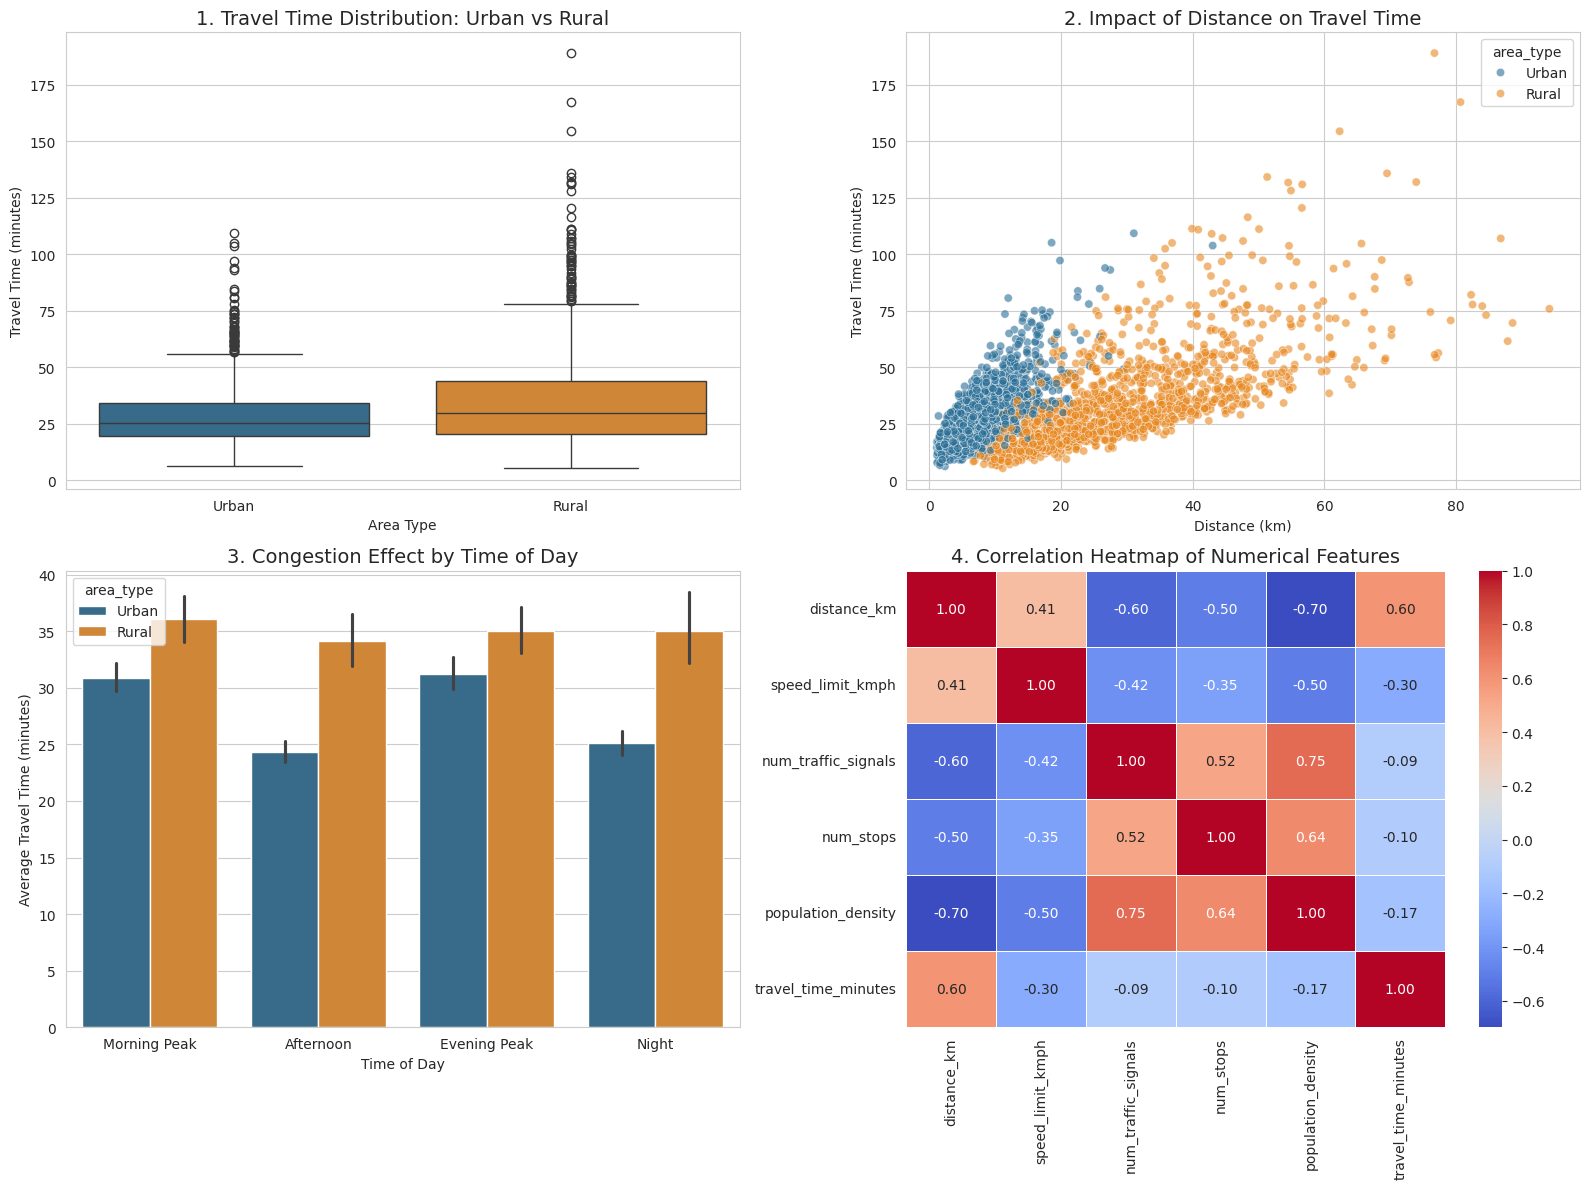

In [3]:
# STEP 3: Data Visualization (4 Distinct Graphs)
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Graph 1: Boxplot of Travel Time by Area Type
sns.boxplot(data=df, x="area_type", y="travel_time_minutes", ax=axes[0, 0], palette=["#2A6F97", "#E8871E"])
axes[0, 0].set_title("1. Travel Time Distribution: Urban vs Rural", fontsize=14)
axes[0, 0].set_ylabel("Travel Time (minutes)")
axes[0, 0].set_xlabel("Area Type")

# Graph 2: Scatter plot of Distance vs Travel Time
sns.scatterplot(data=df, x="distance_km", y="travel_time_minutes", hue="area_type", alpha=0.6, palette=["#2A6F97", "#E8871E"], ax=axes[0, 1])
axes[0, 1].set_title("2. Impact of Distance on Travel Time", fontsize=14)
axes[0, 1].set_ylabel("Travel Time (minutes)")
axes[0, 1].set_xlabel("Distance (km)")

# Graph 3: Bar chart for Average Travel Time by Time of Day
time_order = ["Morning Peak", "Afternoon", "Evening Peak", "Night"]
sns.barplot(data=df, x="time_of_day", y="travel_time_minutes", hue="area_type", order=time_order, palette=["#2A6F97", "#E8871E"], ax=axes[1, 0])
axes[1, 0].set_title("3. Congestion Effect by Time of Day", fontsize=14)
axes[1, 0].set_ylabel("Average Travel Time (minutes)")
axes[1, 0].set_xlabel("Time of Day")

# Graph 4: Correlation Heatmap of Numerical Features
numeric_df = df[numeric_cols + [target]]
corr_matrix = numeric_df.corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1, 1], linewidths=0.5)
axes[1, 1].set_title("4. Correlation Heatmap of Numerical Features", fontsize=14)

plt.tight_layout()
plt.show()

In [6]:
# STEP 4: Model Training (Training 4 Distinct Regressors)

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import pandas as pd

print("Initializing and training 4 different regressors...")

# Initialize the 4 models mentioned in the presentation
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

# Dictionary to store the predictions for later evaluation
predictions_dict = {}

# Train each model
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_scaled, y_train)

    # Store predictions on the test set
    predictions_dict[name] = model.predict(X_test_scaled)

print("\nAll 4 models successfully trained on the 80% training split.")

Initializing and training 4 different regressors...
Training Linear Regression...
Training Decision Tree...
Training Random Forest...
Training Gradient Boosting...

All 4 models successfully trained on the 80% training split.


Please upload your 'travel_time_dataset.csv' file:


Saving travel_time_dataset (1).csv to travel_time_dataset (1) (1).csv

--- First 5 Rows ---


,area_type,distance_km,road_type,speed_limit_kmph,num_traffic_signals,num_stops,population_density,weather,time_of_day,travel_time_minutes
0,Urban,12.16,Main Road,46.3,9,3,10153.0,Clear,Night,29.20
1,Rural,29.54,Street,31.7,0,1,876.0,Rain,Night,69.98
2,Rural,20.51,Main Road,49.8,0,1,381.0,Clear,Evening Peak,25.84
3,Rural,30.26,Street,27.9,0,1,648.0,Clear,Evening Peak,72.30
4,Urban,5.22,Street,20.0,8,3,7518.0,Clear,Evening Peak,37.27



--- Model Evaluation ---
MSE: 68.50723951573389
RMSE: 8.276910022208401
R2 Score: 0.7754802954695404


/tmp/ipykernel_972/3813000876.py:54: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot(lims, lims, "k--", linewidth=1.5, color='red', label="Perfect Prediction")


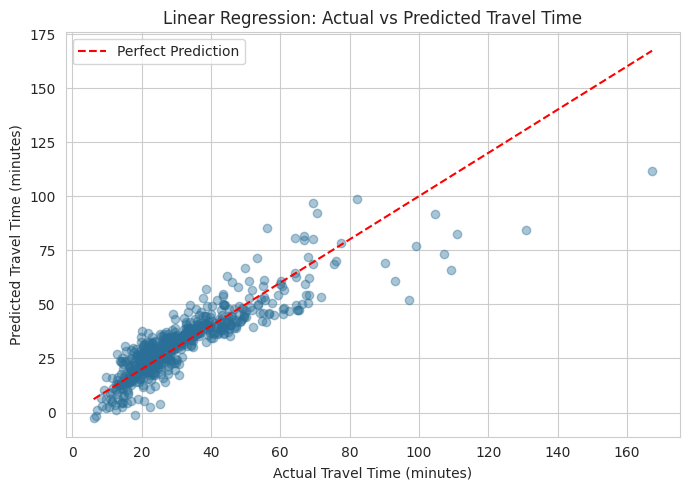

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from google.colab import files
import io

# 1. Load Dataset (CSV Upload)
print("Please upload your 'travel_time_dataset.csv' file:")
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# Drop any missing values just in case
df = df.dropna()

print("\n--- First 5 Rows ---")
display(df.head())

# 2. Define Features and Target
target = 'travel_time_minutes'

# Separate features (X) and target variable (y)
X_raw = df.drop(target, axis=1)
y = df[target]

# One-hot encode categorical columns (Urban/Rural, Weather, etc.) so Linear Regression can read them
X = pd.get_dummies(X_raw, drop_first=True)

# 3. Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Train the Model
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Predict
y_pred = model.predict(X_test)

# 6. Evaluate
print("\n--- Model Evaluation ---")
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)
print("R2 Score:", r2_score(y_test, y_pred))

# 7. Visualize Results
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.4, color='#2A6F97')

# Draw a diagonal dashed line representing perfect predictions
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "k--", linewidth=1.5, color='red', label="Perfect Prediction")

plt.xlabel("Actual Travel Time (minutes)")
plt.ylabel("Predicted Travel Time (minutes)")
plt.title("Linear Regression: Actual vs Predicted Travel Time")
plt.legend()
plt.tight_layout()
plt.show()

In [7]:

# STEP 5: Evaluation & Urban-Rural Error Breakdown

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("--- OVERALL MODEL COMPARISON ---")
results = []

# Calculate MAE, RMSE, and R2 for each model
for name, y_pred in predictions_dict.items():
    mae = mean_absolute_error(y_test, y_pred)
    rmse = mean_squared_error(y_test, y_pred) ** 0.5
    r2 = r2_score(y_test, y_pred)
    results.append({"Model": name, "MAE (min)": round(mae, 2), "RMSE (min)": round(rmse, 2), "R2 Score": round(r2, 3)})

# Display results sorted by highest R2 Score
results_df = pd.DataFrame(results).sort_values(by="R2 Score", ascending=False).reset_index(drop=True)
display(results_df)

# Identify the winning model automatically
best_model_name = results_df.iloc[0]["Model"]
best_pred = predictions_dict[best_model_name]

print(f"\nWINNING MODEL: {best_model_name}")

# Calculate prediction error specifically for Urban vs Rural using the best model
error_df = X_test_raw.copy()
error_df["actual"] = y_test.values
error_df["predicted"] = best_pred
error_df["abs_error"] = (error_df["actual"] - error_df["predicted"]).abs()

urban_mae = error_df.loc[error_df.area_type == "Urban", "abs_error"].mean()
rural_mae = error_df.loc[error_df.area_type == "Rural", "abs_error"].mean()

print("\n--- URBAN VS RURAL ERROR BREAKDOWN ---")
print(f"Urban Average Error: {urban_mae:.2f} minutes")
print(f"Rural Average Error: {rural_mae:.2f} minutes")

--- OVERALL MODEL COMPARISON ---


,Model,MAE (min),RMSE (min),R2 Score
0,Gradient Boosting,2.92,4.03,0.947
1,Random Forest,3.25,4.49,0.934
2,Decision Tree,4.57,6.48,0.863
3,Linear Regression,5.70,8.28,0.775



WINNING MODEL: Gradient Boosting

--- URBAN VS RURAL ERROR BREAKDOWN ---
Urban Average Error: 3.00 minutes
Rural Average Error: 2.82 minutes


Please upload your 'travel_time_dataset.csv' file:


Saving travel_time_dataset (1).csv to travel_time_dataset (1) (2).csv

--- Model Evaluation ---
MAE: 7.94 minutes
RMSE: 10.51 minutes
R2 Score: 0.638


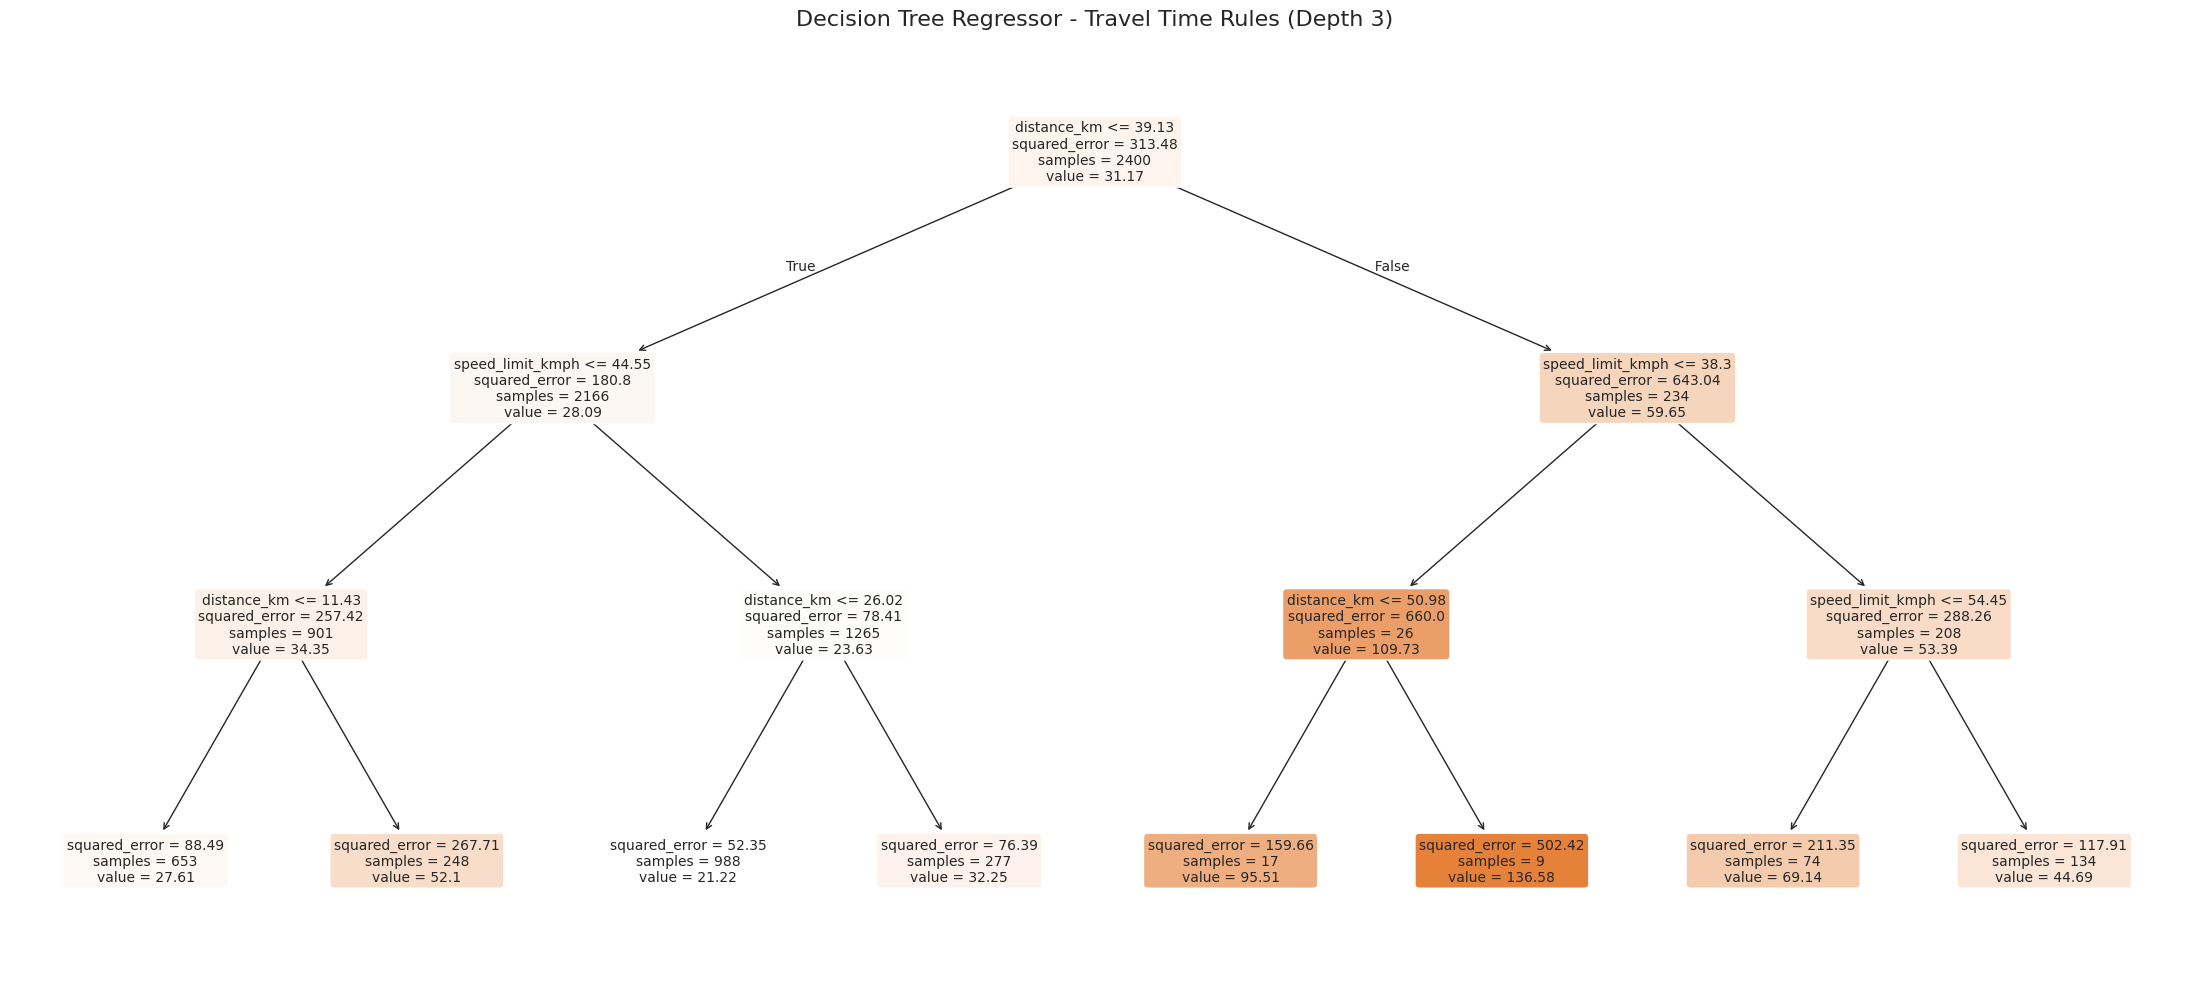

In [10]:

# TRAVEL TIME PREDICTION: URBAN-RURAL ML MODEL
# Practical 5.1: Construct decision trees and visualize them

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from google.colab import files
import io

# 1. Load Dataset (CSV Upload)
print("Please upload your 'travel_time_dataset.csv' file:")
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[file_name])).dropna()

# 2. Define Features and Target
target = 'travel_time_minutes'

# Separate features (X) and target variable (y)
X_raw = df.drop(target, axis=1)
y = df[target]

# One-hot encode categorical columns so the Decision Tree can process them
X = pd.get_dummies(X_raw, drop_first=True)

# 3. Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Train the Model
# Note: We use DecisionTreeRegressor instead of Classifier because travel time is a continuous number.
# max_depth is set to 3 so the visual plot remains readable on the screen.
dt_model = DecisionTreeRegressor(max_depth=3, random_state=42)
dt_model.fit(X_train, y_train)

# 5. Predict and Evaluate
y_pred = dt_model.predict(X_test)

print("\n--- Model Evaluation ---")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.2f} minutes")
print(f"RMSE: {mean_squared_error(y_test, y_pred) ** 0.5:.2f} minutes")
print(f"R2 Score: {r2_score(y_test, y_pred):.3f}")

# 6. Visualize the Tree
plt.figure(figsize=(22, 10))
plot_tree(dt_model,
          feature_names=X.columns,
          filled=True,
          rounded=True,
          fontsize=10,
          precision=2)

plt.title("Decision Tree Regressor - Travel Time Rules (Depth 3)", fontsize=16)
plt.tight_layout()
plt.show()

Please upload your 'travel_time_dataset.csv' file:


Saving travel_time_dataset (1).csv to travel_time_dataset (1) (4).csv

Training models and calculating R2 scores...


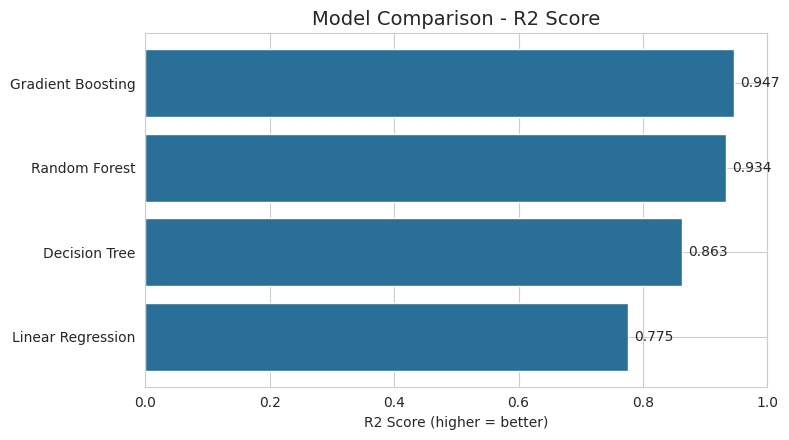

In [14]:

# TRAVEL TIME PREDICTION: URBAN-RURAL ML MODEL
# Model Comparison: R2 Score for 4 Regressors

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score
from google.colab import files
import io

# 1. Load Dataset (CSV Upload)
print("Please upload your 'travel_time_dataset.csv' file:")
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[file_name])).dropna()

# 2. Data Preprocessing
target = "travel_time_minutes"
categorical_cols = ["area_type", "road_type", "weather", "time_of_day"]
numeric_cols = ["distance_km", "speed_limit_kmph", "num_traffic_signals", "num_stops", "population_density"]

X_raw = df.drop(target, axis=1)
y = df[target]

# One-hot encode categories
X = pd.get_dummies(X_raw, columns=categorical_cols, drop_first=True)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale numeric features
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

# 3. Initialize the 4 Models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

results = []

# 4. Train Models and Calculate R2 Scores
print("\nTraining models and calculating R2 scores...")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    r2 = r2_score(y_test, y_pred)
    results.append({"Model": name, "R2 Score": r2})

# Convert to DataFrame and sort from lowest to highest for the bar chart
results_df = pd.DataFrame(results).sort_values(by="R2 Score", ascending=True)

# 5. Visualize Model Comparison R2 Graph
plt.figure(figsize=(8, 4.5))
bars = plt.barh(results_df["Model"], results_df["R2 Score"], color="#2A6F97")

plt.xlabel("R2 Score (higher = better)")
plt.title("Model Comparison - R2 Score", fontsize=14)
plt.xlim(0, 1)

# Add the exact score numbers to the end of each bar
for b in bars:
    plt.text(b.get_width() + 0.01, b.get_y() + b.get_height()/2,
             f"{b.get_width():.3f}", va="center", fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:

# STEP 6: URBAN vs RURAL ERROR BREAKDOWN (the core comparison of this project)

error_df = X_test_raw.copy()
error_df["actual"] = y_test.values
error_df["predicted"] = best_preds
error_df["abs_error"] = (error_df["actual"] - error_df["predicted"]).abs()

urban_mae = error_df.loc[error_df.area_type == "Urban", "abs_error"].mean()
rural_mae = error_df.loc[error_df.area_type == "Rural", "abs_error"].mean()
print("STEP 6: Urban vs Rural MAE using best model")
print(f"  Urban MAE : {urban_mae:.2f} min")
print(f"  Rural MAE : {rural_mae:.2f} min\n")

Please upload your 'travel_time_dataset.csv' file:


Saving travel_time_dataset (1).csv to travel_time_dataset (1) (3).csv

--- Model Evaluation ---
MAE: 3.25 minutes
RMSE: 4.49 minutes
R2 Score: 0.934


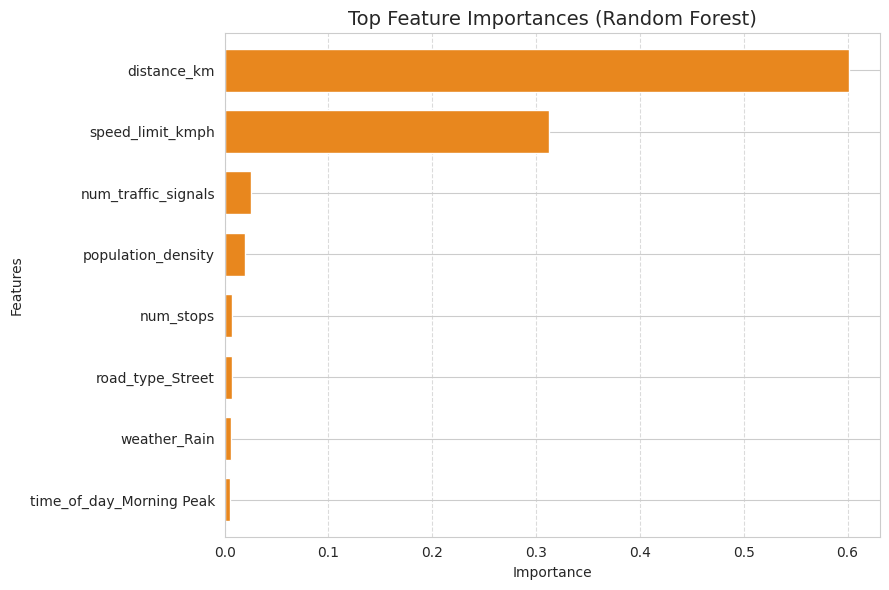

In [11]:

# TRAVEL TIME PREDICTION: URBAN-RURAL ML MODEL
# Step 7: Train and evaluate a random forest model

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from google.colab import files
import io

# 1. Load Dataset (CSV Upload)
print("Please upload your 'travel_time_dataset.csv' file:")
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[file_name])).dropna()

# 2. Define Features and Target
target = 'travel_time_minutes'
X_raw = df.drop(target, axis=1)
y = df[target]

# One-hot encode categorical columns
X = pd.get_dummies(X_raw, drop_first=True)

# 3. Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Train the Model (RandomForestRegressor for continuous target)
rf_model = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42)
rf_model.fit(X_train, y_train)

# 5. Predict and Evaluate
y_pred = rf_model.predict(X_test)

print("\n--- Model Evaluation ---")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.2f} minutes")
print(f"RMSE: {mean_squared_error(y_test, y_pred) ** 0.5:.2f} minutes")
print(f"R2 Score: {r2_score(y_test, y_pred):.3f}")

# 6. Visualize Feature Importances
plt.figure(figsize=(9, 6))
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
# Sort to get the top 8 most important features for a cleaner chart
top_importances = importances.sort_values(ascending=True).tail(8)

top_importances.plot(kind='barh', color="#E8871E", width=0.7)
plt.title("Top Feature Importances (Random Forest)", fontsize=14)
plt.xlabel("Importance")
plt.ylabel("Features")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()